[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/05_database-internals.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 5 of 21*

# How Databases Work

What's inside a database: pages, B-trees and indexes, query plans and join algorithms, transactions and isolation levels, write-ahead logs, locks, MVCC and LSM trees. You'll build each one in miniature.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** An index is the index at the back of a book. Everything else in a database exists to avoid reading the whole book.

**What interviewers really test here:** B-trees, join algorithms, reading a query plan, ACID and isolation levels.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why a query can take 1 ms or 1 hour *(Basics)*
- [ ] 2. When indexes help, and when they don't *(Core)*
- [ ] 3. How joins actually run *(Core)*
- [ ] 4. Transactions and ACID *(Core)*
- [ ] 5. MVCC, LSM trees and Bloom filters *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Slow query checklist

1. Run EXPLAIN ANALYZE, and find the most expensive step.
2. Look for full scans of large tables and large row estimate errors.
3. Check that indexes match the filter and join columns, in the right order.
4. Avoid functions on indexed columns.
5. Update statistics with ANALYZE.
6. Select fewer columns, and filter earlier.
7. Consider partitioning or a summary table.

---
# Part 2: Lessons, step by step

## Lesson 1: Why a query can take 1 ms or 1 hour

*Level: Basics*

Disks read data in blocks called **pages**, often about 8 KB each. Reading from disk is vastly slower than from memory, so database design is largely about reading as few pages as possible.



With 1,000,000 rows of 100 bytes, 8,000-byte pages hold 80 rows each. That's 12,500 pages, or 100 MB.



**An index is like the index at the back of a book.** Without one, finding a row may mean reading everything:



| Rows | Full scan, worst case | Index (binary search) |
| --- | --- | --- |
| 1 million | 1,000,000 comparisons | **20** |
| 1 billion | 1,000,000,000 comparisons | **30** |



The chart shows how differently these grow.



**A B-tree** is the usual index. It's not a binary tree: each node is a whole page, holding hundreds of keys, so the tree is wide and very short. With 500 children per node, 1 billion rows need only **4 levels**, or about 4 page reads, and the top levels are usually already in memory. Leaves are linked in order, so ranges are fast too: find the start, then walk along.



**Indexes aren't free.** Each insert updates every index. With 4 indexes, 1,000 inserts cost 5,000 writes, which is 5 times the work. Don't index everything.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

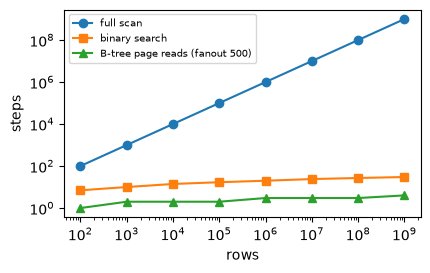

In [2]:
def scan_vs_index_chart():
    n = np.logspace(2, 9, 8)
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.loglog(n, n, "o-", label="full scan")
    ax.loglog(n, np.ceil(np.log2(n)), "s-", label="binary search")
    ax.loglog(n, np.ceil(np.log(n) / np.log(500)), "^-", label="B-tree page reads (fanout 500)")
    ax.set_xlabel("rows")
    ax.set_ylabel("steps")
    ax.legend(fontsize=7)


scan_vs_index_chart()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q7](#q7), [Q3](#q3), [Q6](#q6), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 2: When indexes help, and when they don't

*Level: Core*

**Column order matters in a composite index.** An index on (last\_name, first\_name) works like a phone book. You can find "Smith", or "Smith, Sam", but not everyone named "Sam".



| Index (a, b, c), query filters on | Columns usable |
| --- | --- |
| a, b | 2 |
| b, c | 0 |
| a, c | 1, because the run stops at the gap |



**Selectivity** is distinct values ÷ rows. With 900,000 emails in 1M rows, it's 0.9, so an index helps enormously. With a true/false column, it's almost 0. An index would jump around the disk fetching half the table, so a scan is often faster, and the optimiser knows this.



**Things that stop an index being used:**



- A function on the column: `WHERE YEAR(d) = 2026`. Write a range instead.
- A leading wildcard: `LIKE '%son'`.
- A type mismatch between the column and the value.



**Read the plan.** `EXPLAIN` shows what the database will do. Learning to read plans is one of the highest-value database skills there is.



```python
EXPLAIN ANALYZE SELECT * FROM orders WHERE user_id = 7;
-- Index Scan using idx_user ... rows=12 ... time=0.05ms   good
-- Seq Scan on orders ... rows=9000000 ... time=4000ms     look closer
```

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q4](#q4), [Q13](#q13). Try one now, or carry on and do them in Part 3.

## Lesson 3: How joins actually run

*Level: Core*

You write JOIN, and the optimiser chooses an algorithm. Spark and warehouses use the same ones, so this pays off for your whole career.



**Nested loop:** for each left row, check every right row. 2 × 3 rows means 6 comparisons, but with a million rows each side, that's 10¹². It's only good when one side is tiny and the other has an index.



**Hash join:** build a dictionary on the smaller side, then probe with the larger. It's O(n + m), which makes it the workhorse for equality joins, but it needs memory for the hash table.



**Sort-merge join:** sort both, then walk them with two pointers. It suits inputs that are already sorted or too large for memory.



```text
left:  1  2  2        right: 2  2  3
       ↑                     ↑        1 < 2: move left
          ↑                  ↑        match: pair the runs of 2s
```



| Algorithm | Good for | Bad for |
| --- | --- | --- |
| Index nested loop | few rows, indexed | large joins |
| Hash | large equality joins | low memory, ranges |
| Sort-merge | huge or sorted data | sorting cost when not sorted |



**Why plans go wrong:** the optimiser estimates rows using statistics, multiplying selectivities: 1M × 0.1 × 0.5 = 50,000. But if two columns are correlated, such as city and postal code, the real number is much higher. So stale statistics or correlation can mean a terrible plan. Fix it with `ANALYZE`.

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q9](#q9), [Q16](#q16), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 4: Transactions and ACID

*Level: Core*

Move money: subtract from A, add to B. If it crashes in between, money vanishes. A **transaction** groups steps so they succeed or fail together.



| Letter | Promise | Example |
| --- | --- | --- |
| **A**tomic | all or nothing | the second transfer fails, so the first is undone |
| **C**onsistent | rules always hold | a balance can't go negative |
| **I**solated | transactions don't interfere | see below |
| **D**urable | committed means safe | survives a crash |



**Durability comes from a write-ahead log.** Before changing data, the database appends the change to a log file. After a crash, it replays the log and applies only committed transactions. In our example, transaction 2 never committed, so `a = 9` is ignored, and a stays 1.



**Change data capture reads this same log** to stream changes out of a database, as you'll see later.



**Isolation problems.** Two people each read a counter of 0, and write 0 + 1. The result's **1, not 2**: a **lost update**.



| Level | Prevents |
| --- | --- |
| Read committed | seeing uncommitted data |
| Repeatable read | a row changing between your reads |
| Serializable | all anomalies; safest and slowest |



**Locks and deadlocks.** If T1 waits for T2 while T2 waits for T1, neither can go on. Databases detect this cycle, and abort one transaction, so your code should be able to retry.

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q11](#q11), [Q12](#q12), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 5: MVCC, LSM trees and Bloom filters

*Level: Advanced*

**MVCC (multi-version concurrency control).** Instead of making readers wait, the database keeps several versions of each row. A reader who started at time 12 sees the version committed at time 10, and ignores the one at 20. So **readers don't block writers**. PostgreSQL works this way, and so do lakehouse table formats, through snapshots.



**B-trees vs LSM trees.** B-trees update in place, which is good for reads. **LSM trees** make writes very fast:



1. Writes go to a memory table.
2. When it's full, it's flushed to disk as a sorted, unchangeable file.
3. Reads check memory, then files from newest to oldest.
4. Background **compaction** merges files.



|   | B-tree | LSM tree |
| --- | --- | --- |
| Writes | slower, in place | very fast, append |
| Reads | predictable | may check many files |
| Used in | PostgreSQL, MySQL | Cassandra, RocksDB, HBase |



**Bloom filters** save an LSM tree from reading files that don't have your key. A Bloom filter answers "**definitely not here**" or "**maybe here**", using very little memory. It can be wrong in only one direction: it can say maybe when the key's absent, but never no when it's present. Parquet and Spark use them to skip data too.

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q19](#q19), [Q20](#q20). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
import bisect


<a id="q1"></a>
### Q1. Scan vs Index: Comparisons

🟢 Warm-up · *Why indexes exist*

Return (worst-case comparisons for a full scan, comparisons for binary search) on n rows.

**Examples**

- `n = 1000000` → `(1000000, 20)`
- `n = 1000000000` → `(1000000000, 30)`

In [ ]:
def scan_vs_index(n):
    """
    Return (worst-case comparisons for a full scan, comparisons for binary
    search) on n rows.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scan_vs_index, [
    ((1000000,), (1000000, 20)),
    ((1000000000,), (1000000000, 30)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Halve in a loop to count the steps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ceil(log2(n + 1))`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Halve in a loop to count the steps.

```python
def scan_vs_index(n):
    steps, size = 0, n
    while size > 0:
        size //= 2
        steps += 1
    return (n, steps)
```

**Cost:** O(log n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `ceil(log2(n + 1))`.

```python
def scan_vs_index(n):
    return (n, math.ceil(math.log2(n + 1)))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Halve in a loop to count the steps. That costs O(log n) time and O(1) space."

"I can do better: `ceil(log2(n + 1))`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/scan-vs-index-comparisons)

<a id="q2"></a>
### Q2. Index Lookup in a Sorted List

🟢 Warm-up · *The core idea*

keys is sorted, and rows parallel to it. Return the row for a key, or None.

**Examples**

- `keys = [1, 3, 7], rows = ['a', 'b', 'c'], key = 3` → `'b'`
- `keys = [1, 3, 7], rows = ['a', 'b', 'c'], key = 4` → `None`

In [ ]:
def index_lookup(keys, rows, key):
    """
    keys is sorted, and rows parallel to it. Return the row for a key, or None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(index_lookup, [
    (([1, 3, 7], ['a', 'b', 'c'], 3), 'b'),
    (([1, 3, 7], ['a', 'b', 'c'], 4), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`bisect`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan.

```python
def index_lookup(keys, rows, key):
    for k, r in zip(keys, rows):
        if k == key:
            return r
    return None
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `bisect`.

```python
def index_lookup(keys, rows, key):
    i = bisect.bisect_left(keys, key)
    return rows[i] if i < len(keys) and keys[i] == key else None
```

**Cost:** O(log n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan. That costs O(n) time and O(1) space."

"I can do better: `bisect`. That's O(log n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/index-lookup-in-a-sorted-list)

<a id="q3"></a>
### Q3. Range Scan With an Index

🟢 Warm-up · *Sorted data helps ranges*

Return values in sorted keys with lo ≤ key ≤ hi, and how many rows were examined after finding the start.

**Examples**

- `keys = [1, 3, 5, 7, 9, 11], lo = 4, hi = 9` → `([5, 7, 9], 3)`

In [ ]:
def range_scan(keys, lo, hi):
    """
    Return values in sorted keys with lo ≤ key ≤ hi, and how many rows were
    examined after finding the start.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(range_scan, [
    (([1, 3, 5, 7, 9, 11], 4, 9), ([5, 7, 9], 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan everything: examined = n.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Binary search for the start and end.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan everything: examined = n.

```python
def range_scan(keys, lo, hi):
    out = []
    for k in keys:
        if lo <= k <= hi:
            out.append(k)
    return (out, len(out))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Binary search for the start and end.

```python
def range_scan(keys, lo, hi):
    a, b = bisect.bisect_left(keys, lo), bisect.bisect_right(keys, hi)
    return (keys[a:b], b - a)
```

**Cost:** O(log n + k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan everything: examined = n. That costs O(n) time and O(k) space."

"I can do better: Binary search for the start and end. That's O(log n + k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/range-scan-with-an-index)

<a id="q4"></a>
### Q4. Selectivity

🟢 Warm-up · *Is the index worth using?*

Selectivity = distinct values ÷ rows. Return it, rounded to 4 decimals, and 'index' if at least 0.01, otherwise 'scan'.

**Examples**

- `rows = 1000000, distinct = 900000` → `(0.9, 'index')`
- `rows = 1000000, distinct = 2` → `(0.0, 'scan')`

In [ ]:
def selectivity(rows, distinct):
    """
    Selectivity = distinct values ÷ rows. Return it, rounded to 4 decimals, and
    'index' if at least 0.01, otherwise 'scan'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(selectivity, [
    ((1000000, 900000), (0.9, 'index')),
    ((1000000, 2), (0.0, 'scan')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute, then compare.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A conditional expression.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute, then compare.

```python
def selectivity(rows, distinct):
    s = distinct / rows
    if s >= 0.01:
        choice = "index"
    else:
        choice = "scan"
    return (round(s, 4), choice)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A conditional expression.

```python
def selectivity(rows, distinct):
    s = distinct / rows
    return (round(s, 4), "index" if s >= 0.01 else "scan")
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute, then compare. That costs O(1) time and O(1) space."

"I can do better: A conditional expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/selectivity)

<a id="q5"></a>
### Q5. Nested Loop Join

🟢 Warm-up · *The simplest join*

Join lists of (key, value) on key. Return (rows as [key, left, right], comparisons made).

**Examples**

- `left = [(1, 'a'), (2, 'b')], right = [(2, 'x'), (2, 'y'), (3, 'z')]` → `([[2, 'b', 'x'], [2, 'b', 'y']], 6)`

In [ ]:
def nested_loop(left, right):
    """
    Join lists of (key, value) on key. Return (rows as [key, left, right],
    comparisons made).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(nested_loop, [
    (([(1, 'a'), (2, 'b')], [(2, 'x'), (2, 'y'), (3, 'z')]), ([[2, 'b', 'x'], [2, 'b', 'y']], 6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension, with comparisons being n × m.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Two nested loops.

```python
def nested_loop(left, right):
    out, comparisons = [], 0
    for lk, lv in left:
        for rk, rv in right:
            comparisons += 1
            if lk == rk:
                out.append([lk, lv, rv])
    return (out, comparisons)
```

**Cost:** O(n·m) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension, with comparisons being n × m.

```python
def nested_loop(left, right):
    return ([[lk, lv, rv] for lk, lv in left for rk, rv in right if lk == rk], len(left) * len(right))
```

**Cost:** O(n·m) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two nested loops. That costs O(n·m) time and O(r) space."

"I can do better: A comprehension, with comparisons being n × m. That's O(n·m) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/nested-loop-join)

<a id="q6"></a>
### Q6. Rows per Page

🟢 Warm-up · *Disk works in pages*

With 8,000-byte pages, return (rows per page, pages needed, MB on disk with MB = 10⁶ bytes) for n rows of a given size.

**Examples**

- `n = 1000000, row_size = 100` → `(80, 12500, 100.0)`

In [ ]:
def pages_needed(n, row_size):
    """
    With 8,000-byte pages, return (rows per page, pages needed, MB on disk with
    MB = 10⁶ bytes) for n rows of a given size.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pages_needed, [
    ((1000000, 100), (80, 12500, 100.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact, with `ceil`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Divide step by step.

```python
def pages_needed(n, row_size):
    per_page = 8000 // row_size
    pages = n // per_page
    if n % per_page:
        pages += 1
    return (per_page, pages, pages * 8000 / 1e6)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact, with `ceil`.

```python
def pages_needed(n, row_size):
    per = 8000 // row_size
    p = math.ceil(n / per)
    return (per, p, p * 8000 / 1e6)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide step by step. That costs O(1) time and O(1) space."

"I can do better: Compact, with `ceil`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/rows-per-page)

<a id="q7"></a>
### Q7. B-Tree Height

🟡 Interview standard · *Why so few disk reads?*

A B-tree node holds fanout children. Return how many levels are needed for n rows: the smallest h with fanout^h ≥ n.

**Examples**

- `n = 1000000000, fanout = 500` → `4`
- `n = 1000000, fanout = 2` → `20`

In [ ]:
def btree_height(n, fanout):
    """
    A B-tree node holds fanout children. Return how many levels are needed for n
    rows: the smallest h with fanout^h ≥ n.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(btree_height, [
    ((1000000000, 500), 4),
    ((1000000, 2), 20),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply until it's big enough.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A logarithm can have rounding error, so integer multiplication is safer; shown with a compact loop.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Multiply until it's big enough.

```python
def btree_height(n, fanout):
    height, capacity = 0, 1
    while capacity < n:
        capacity *= fanout
        height += 1
    return height
```

**Cost:** O(h) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A logarithm can have rounding error, so integer multiplication is safer; shown with a compact loop.

```python
def btree_height(n, fanout):
    h = 0
    while fanout ** h < n:
        h += 1
    return h
```

**Cost:** O(h) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply until it's big enough. That costs O(h) time and O(1) space."

"I can do better: A logarithm can have rounding error, so integer multiplication is safer; shown with a compact loop. That's O(h) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/b-tree-height)

<a id="q8"></a>
### Q8. Composite Index: Leftmost Rule

🟡 Interview standard · *Column order matters*

An index on columns index\_cols can use a query's equality columns only as a leftmost run. Return how many index columns are usable.

**Examples**

- `index_cols = ['a', 'b', 'c'], query_cols = ['a', 'b']` → `2`
- `index_cols = ['a', 'b', 'c'], query_cols = ['b', 'c']` → `0`
- `index_cols = ['a', 'b', 'c'], query_cols = ['a', 'c']` → `1`

In [ ]:
def usable_prefix(index_cols, query_cols):
    """
    An index on columns index_cols can use a query's equality columns only as a
    leftmost run. Return how many index columns are usable.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(usable_prefix, [
    ((['a', 'b', 'c'], ['a', 'b']), 2),
    ((['a', 'b', 'c'], ['b', 'c']), 0),
    ((['a', 'b', 'c'], ['a', 'c']), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk the index columns until one is missing.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set for the query's columns.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Walk the index columns until one is missing.

```python
def usable_prefix(index_cols, query_cols):
    n = 0
    for col in index_cols:
        if col in query_cols:
            n += 1
        else:
            break
    return n
```

**Cost:** O(i·q) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set for the query's columns.

```python
def usable_prefix(index_cols, query_cols):
    wanted = set(query_cols)
    import itertools
    return len(list(itertools.takewhile(wanted.__contains__, index_cols)))
```

**Cost:** O(i + q) time, O(q) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk the index columns until one is missing. That costs O(i·q) time and O(1) space."

"I can do better: A set for the query's columns. That's O(i + q) time and O(q) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/composite-index-leftmost-rule)

<a id="q9"></a>
### Q9. Hash Join

🟡 Interview standard · *The workhorse*

Build a hash table on the right list, then probe with the left. Return rows as [key, left, right], in probe order. It should give the same rows as a nested loop.

**Examples**

- `left = [(1, 'a'), (2, 'b')], right = [(2, 'x'), (2, 'y'), (3, 'z')]` → `[[2, 'b', 'x'], [2, 'b', 'y']]`

In [ ]:
def hash_join(left, right):
    """
    Build a hash table on the right list, then probe with the left. Return rows
    as [key, left, right], in probe order. It should give the same rows as a
    nested loop.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hash_join, [
    (([(1, 'a'), (2, 'b')], [(2, 'x'), (2, 'y'), (3, 'z')]), [[2, 'b', 'x'], [2, 'b', 'y']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Build, then probe. Build on the smaller side to save memory.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Nested loops.

```python
def hash_join(left, right):
    return [[lk, lv, rv] for lk, lv in left for rk, rv in right if lk == rk]
```

**Cost:** O(n·m) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Build, then probe. Build on the smaller side to save memory.

```python
def hash_join(left, right):
    table = {}
    for k, v in right:
        table.setdefault(k, []).append(v)
    return [[k, v, r] for k, v in left for r in table.get(k, [])]
```

**Cost:** O(n + m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(n·m) time and O(r) space."

"I can do better: Build, then probe. Build on the smaller side to save memory. That's O(n + m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/hash-join)

<a id="q10"></a>
### Q10. Atomic Transfer

🟡 Interview standard · *All or nothing*

Apply transfers (from, to, amount) as a transaction on a balances dictionary: if any would go negative, roll back everything. Return (committed, final balances).

**Examples**

- `balances = {'a': 10, 'b': 0}, transfers = [('a', 'b', 5), ('a', 'b', 4)]` → `(True, {'a': 1, 'b': 9})`
- `balances = {'a': 10, 'b': 0}, transfers = [('a', 'b', 5), ('a', 'b', 6)]` → `(False, {'a': 10, 'b': 0})`

In [ ]:
def atomic_transfer(balances, transfers):
    """
    Apply transfers (from, to, amount) as a transaction on a balances
    dictionary: if any would go negative, roll back everything. Return
    (committed, final balances).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(atomic_transfer, [
    (({'a': 10, 'b': 0}, [('a', 'b', 5), ('a', 'b', 4)]), (True, {'a': 1, 'b': 9})),
    (({'a': 10, 'b': 0}, [('a', 'b', 5), ('a', 'b', 6)]), (False, {'a': 10, 'b': 0})),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Work on a copy, replacing the original only if all succeed.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Keep an undo log and reverse it on failure, as real databases do.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Work on a copy, replacing the original only if all succeed.

```python
def atomic_transfer(balances, transfers):
    work = dict(balances)
    for src, dst, amount in transfers:
        if work[src] < amount:
            return (False, balances)
        work[src] -= amount
        work[dst] += amount
    return (True, work)
```

**Cost:** O(k + t) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Keep an undo log and reverse it on failure, as real databases do.

```python
def atomic_transfer(balances, transfers):
    undo = []
    for src, dst, amount in transfers:
        if balances[src] < amount:
            for s, d, a in reversed(undo):
                balances[s] += a
                balances[d] -= a
            return (False, balances)
        balances[src] -= amount
        balances[dst] += amount
        undo.append((src, dst, amount))
    return (True, balances)
```

**Cost:** O(t) time, O(t) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Work on a copy, replacing the original only if all succeed. That costs O(k + t) time and O(k) space."

"I can do better: Keep an undo log and reverse it on failure, as real databases do. That's O(t) time and O(t) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/atomic-transfer)

<a id="q11"></a>
### Q11. Recover From a Write-Ahead Log

🟡 Interview standard · *Durability*

After a crash, replay the log: ('set', txn, key, value) and ('commit', txn). Only committed transactions count. Return the final state.

**Examples**

- `log = [('set', 1, 'a', 1), ('commit', 1), ('set', 2, 'a', 9), ('set', 3, 'b', 2), ('commit', 3)]` → `{'a': 1, 'b': 2}`

In [ ]:
def recover(log):
    """
    After a crash, replay the log: ('set', txn, key, value) and ('commit', txn).
    Only committed transactions count. Return the final state.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(recover, [
    (([('set', 1, 'a', 1), ('commit', 1), ('set', 2, 'a', 9), ('set', 3, 'b', 2), ('commit', 3)],), {'a': 1, 'b': 2}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two passes: find the committed ones, then apply.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One pass, buffering each transaction until it commits.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Two passes: find the committed ones, then apply.

```python
def recover(log):
    committed = {e[1] for e in log if e[0] == "commit"}
    state = {}
    for e in log:
        if e[0] == "set" and e[1] in committed:
            state[e[2]] = e[3]
    return dict(sorted(state.items()))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One pass, buffering each transaction until it commits.

```python
def recover(log):
    pending, state = {}, {}
    for e in log:
        if e[0] == "set":
            pending.setdefault(e[1], []).append(e[2:])
        else:
            state.update(pending.pop(e[1], []))
    return dict(sorted(state.items()))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two passes: find the committed ones, then apply. That costs O(n) time and O(n) space."

"I can do better: One pass, buffering each transaction until it commits. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/recover-from-a-write-ahead-log)

<a id="q12"></a>
### Q12. Lost Update

🟡 Interview standard · *Why isolation matters*

Two transactions each read a counter, then write read + 1. Given an order such as ['r1', 'r2', 'w1', 'w2'], return the final value starting from 0.

**Examples**

- `order = ['r1', 'w1', 'r2', 'w2']` → `2`
- `order = ['r1', 'r2', 'w1', 'w2']` → `1`

In [ ]:
def lost_update(order):
    """
    Two transactions each read a counter, then write read + 1. Given an order
    such as ['r1', 'r2', 'w1', 'w2'], return the final value starting from 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lost_update, [
    ((['r1', 'w1', 'r2', 'w2'],), 2),
    ((['r1', 'r2', 'w1', 'w2'],), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track each transaction's read in variables.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary of reads.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Track each transaction's read in variables.

```python
def lost_update(order):
    value = 0
    read1 = read2 = None
    for op in order:
        if op == "r1":
            read1 = value
        elif op == "r2":
            read2 = value
        elif op == "w1":
            value = read1 + 1
        else:
            value = read2 + 1
    return value
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary of reads.

```python
def lost_update(order):
    value, reads = 0, {}
    for op in order:
        if op[0] == "r":
            reads[op[1]] = value
        else:
            value = reads[op[1]] + 1
    return value
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track each transaction's read in variables. That costs O(n) time and O(1) space."

"I can do better: A dictionary of reads. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/lost-update)

<a id="q13"></a>
### Q13. Estimate Rows After a Filter

🟡 Interview standard · *What the planner guesses*

With independent filters of given selectivities on n rows, return estimated rows, rounded to the nearest whole number. Correlated columns make this estimate wrong.

**Examples**

- `n = 1000000, selectivities = [0.1, 0.5]` → `50000`

In [ ]:
def estimate_rows(n, selectivities):
    """
    With independent filters of given selectivities on n rows, return estimated
    rows, rounded to the nearest whole number. Correlated columns make this
    estimate wrong.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(estimate_rows, [
    ((1000000, [0.1, 0.5]), 50000),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.prod`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Multiply in a loop.

```python
def estimate_rows(n, selectivities):
    value = n
    for s in selectivities:
        value *= s
    return round(value)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `math.prod`.

```python
def estimate_rows(n, selectivities):
    return round(n * math.prod(selectivities))
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply in a loop. That costs O(k) time and O(1) space."

"I can do better: `math.prod`. That's O(k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/estimate-rows-after-a-filter)

<a id="q14"></a>
### Q14. Pick a Join Strategy

🟡 Interview standard · *The optimizer's choice*

Given rows on each side, whether the larger side has an index on the key, and memory in rows: return 'index nested loop' if the smaller side ≤ 1,000 and there's an index; 'hash' if the smaller side fits in memory; otherwise 'sort-merge'.

**Examples**

- `a = 100, b = 1000000, indexed = True, memory = 10000` → `'index nested loop'`
- `a = 5000, b = 1000000, indexed = False, memory = 10000` → `'hash'`
- `a = 500000, b = 1000000, indexed = False, memory = 10000` → `'sort-merge'`

In [ ]:
def join_strategy(a, b, indexed, memory):
    """
    Given rows on each side, whether the larger side has an index on the key,
    and memory in rows: return 'index nested loop' if the smaller side ≤ 1,000
    and there's an index; 'hash' if the smaller side fits in memory; otherwise
    'sort-merge'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(join_strategy, [
    ((100, 1000000, True, 10000), 'index nested loop'),
    ((5000, 1000000, False, 10000), 'hash'),
    ((500000, 1000000, False, 10000), 'sort-merge'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same logic with an expression.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def join_strategy(a, b, indexed, memory):
    small = a if a < b else b
    if small <= 1000 and indexed:
        return "index nested loop"
    if small <= memory:
        return "hash"
    return "sort-merge"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same logic with an expression.

```python
def join_strategy(a, b, indexed, memory):
    small = min(a, b)
    return "index nested loop" if small <= 1000 and indexed else "hash" if small <= memory else "sort-merge"
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(1) time and O(1) space."

"I can do better: Same logic with an expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/pick-a-join-strategy)

<a id="q15"></a>
### Q15. Write Amplification

🟡 Interview standard · *Indexes aren't free*

Each insert writes the row plus one entry per index. Return the writes for n inserts with k indexes, and how many times more than with none.

**Examples**

- `n = 1000, k = 4` → `(5000, 5.0)`

In [ ]:
def write_amp(n, k):
    """
    Each insert writes the row plus one entry per index. Return the writes for n
    inserts with k indexes, and how many times more than with none.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(write_amp, [
    ((1000, 4), (5000, 5.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in steps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A formula.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Count in steps.

```python
def write_amp(n, k):
    per_insert = 1 + k
    total = per_insert * n
    return (total, total / n)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A formula.

```python
def write_amp(n, k):
    return ((1 + k) * n, float(1 + k))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in steps. That costs O(1) time and O(1) space."

"I can do better: A formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/write-amplification)

<a id="q16"></a>
### Q16. Sort-Merge Join

🔴 Stretch · *When both sides are sorted*

Both lists are sorted by key. Merge-join them, handling duplicates.

**Examples**

- `left = [(1, 'a'), (2, 'b'), (2, 'c')], right = [(2, 'x'), (2, 'y'), (3, 'z')]` → `[[2, 'b', 'x'], [2, 'b', 'y'], [2, 'c', 'x'], [2, 'c', 'y']]`

In [ ]:
def merge_join(left, right):
    """
    Both lists are sorted by key. Merge-join them, handling duplicates.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(merge_join, [
    (([(1, 'a'), (2, 'b'), (2, 'c')], [(2, 'x'), (2, 'y'), (3, 'z')]), [[2, 'b', 'x'], [2, 'b', 'y'], [2, 'c', 'x'], [2, 'c', 'y']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops ignore that it's sorted.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Two pointers: advance the smaller side; on a match, pair up the runs.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Nested loops ignore that it's sorted.

```python
def merge_join(left, right):
    return [[lk, lv, rv] for lk, lv in left for rk, rv in right if lk == rk]
```

**Cost:** O(n·m) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Two pointers: advance the smaller side; on a match, pair up the runs.

```python
def merge_join(left, right):
    out, i, j = [], 0, 0
    while i < len(left) and j < len(right):
        if left[i][0] < right[j][0]:
            i += 1
        elif left[i][0] > right[j][0]:
            j += 1
        else:
            key, end = left[i][0], j
            while end < len(right) and right[end][0] == key:
                end += 1
            while i < len(left) and left[i][0] == key:
                out += [[key, left[i][1], right[k][1]] for k in range(j, end)]
                i += 1
            j = end
    return out
```

**Cost:** O(n + m + r) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops ignore that it's sorted. That costs O(n·m) time and O(r) space."

"I can do better: Two pointers: advance the smaller side; on a match, pair up the runs. That's O(n + m + r) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/sort-merge-join)

<a id="q17"></a>
### Q17. MVCC: Which Version Do I See?

🔴 Stretch · *Readers don't block writers*

versions is a list of (value, commit\_time). A reader started at time t sees the latest version committed at or before t, or None.

**Examples**

- `versions = [('a', 5), ('b', 10), ('c', 20)], t = 12` → `'b'`
- `versions = [('a', 5)], t = 1` → `None`

In [ ]:
def visible_version(versions, t):
    """
    versions is a list of (value, commit_time). A reader started at time t sees
    the latest version committed at or before t, or None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(visible_version, [
    (([('a', 5), ('b', 10), ('c', 20)], 12), 'b'),
    (([('a', 5)], 1), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan all versions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Versions are in time order, so binary search.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan all versions.

```python
def visible_version(versions, t):
    best = None
    for value, commit in versions:
        if commit <= t:
            best = value
    return best
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Versions are in time order, so binary search.

```python
def visible_version(versions, t):
    i = bisect.bisect_right([c for _, c in versions], t)
    return versions[i - 1][0] if i else None
```

**Cost:** O(log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan all versions. That costs O(n) time and O(1) space."

"I can do better: Versions are in time order, so binary search. That's O(log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/mvcc-which-version-do-i-see)

<a id="q18"></a>
### Q18. Deadlock Detection

🔴 Stretch · *A cycle in who waits for whom*

waits maps a transaction to the ones it's waiting for. Return whether there's a deadlock.

**Examples**

- `waits = {'t1': ['t2'], 't2': ['t1']}` → `True`
- `waits = {'t1': ['t2'], 't2': ['t3']}` → `False`

In [ ]:
def has_deadlock(waits):
    """
    waits maps a transaction to the ones it's waiting for. Return whether
    there's a deadlock.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(has_deadlock, [
    (({'t1': ['t2'], 't2': ['t1']},), True),
    (({'t1': ['t2'], 't2': ['t3']},), False),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

From each transaction, search for a path back to itself.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

DFS with three colours: finding a grey node means a cycle.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** From each transaction, search for a path back to itself.

```python
def has_deadlock(waits):
    for start in waits:
        stack, seen = list(waits.get(start, [])), set()
        while stack:
            x = stack.pop()
            if x == start:
                return True
            if x not in seen:
                seen.add(x)
                stack += waits.get(x, [])
    return False
```

**Cost:** O(V·(V + E)) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** DFS with three colours: finding a grey node means a cycle.

```python
def has_deadlock(waits):
    state = {}

    def visit(x):
        if state.get(x) == 1:
            return True
        if state.get(x) == 2:
            return False
        state[x] = 1
        found = any(visit(y) for y in waits.get(x, []))
        state[x] = 2
        return found
    return any(visit(x) for x in waits)
```

**Cost:** O(V + E) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: From each transaction, search for a path back to itself. That costs O(V·(V + E)) time and O(V) space."

"I can do better: DFS with three colours: finding a grey node means a cycle. That's O(V + E) time and O(V) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `waits = {'t1': ['t2'], 't2': ['t1']}`

1. visit() returns True
2. GeneratorExit raised: 
3. visit() returns True
4. GeneratorExit raised: 
5. visit() returns True
6. GeneratorExit raised: 
7. has\_deadlock() returns True

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/deadlock-detection)

<a id="q19"></a>
### Q19. A Tiny LSM Tree

🔴 Stretch · *Write-optimised storage*

Writes go to a memtable; when it holds cap keys it's flushed as a new sorted run. Reads check the memtable, then runs from newest to oldest. Apply writes, and return (value of key, number of runs).

**Examples**

- `writes = [('a', 1), ('b', 2), ('a', 3), ('c', 4), ('d', 5)], cap = 2, key = 'a'` → `(3, 2)`

In [ ]:
def lsm(writes, cap, key):
    """
    Writes go to a memtable; when it holds cap keys it's flushed as a new sorted
    run. Reads check the memtable, then runs from newest to oldest. Apply
    writes, and return (value of key, number of runs).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lsm, [
    (([('a', 1), ('b', 2), ('a', 3), ('c', 4), ('d', 5)], 2, 'a'), (3, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Follow the rules with lists of pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Dictionaries for memtable and runs.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Follow the rules with lists of pairs.

```python
def lsm(writes, cap, key):
    mem, runs = [], []
    for k, v in writes:
        mem = [p for p in mem if p[0] != k] + [(k, v)]
        if len(mem) == cap:
            runs.append(sorted(mem))
            mem = []
    for k, v in mem:
        if k == key:
            return (v, len(runs))
    for run in reversed(runs):
        for k, v in run:
            if k == key:
                return (v, len(runs))
    return (None, len(runs))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Dictionaries for memtable and runs.

```python
def lsm(writes, cap, key):
    mem, runs = {}, []
    for k, v in writes:
        mem[k] = v
        if len(mem) == cap:
            runs.append(mem)
            mem = {}
    for layer in [mem] + runs[::-1]:
        if key in layer:
            return (layer[key], len(runs))
    return (None, len(runs))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Follow the rules with lists of pairs. That costs O(n) time and O(n) space."

"I can do better: Dictionaries for memtable and runs. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/a-tiny-lsm-tree)

<a id="q20"></a>
### Q20. Bloom Filter

🔴 Stretch · *Definitely not, or maybe*

Use m bits and two hashes, sum(codes) % m and sum(i × code) % m (i from 1). Add words, then return for each query 'no' if any bit is unset, else 'maybe'.

**Examples**

- `words = ['cat', 'dog'], queries = ['cat', 'bird'], m = 64` → `['maybe', 'no']`

In [ ]:
def bloom(words, queries, m):
    """
    Use m bits and two hashes, sum(codes) % m and sum(i × code) % m (i from 1).
    Add words, then return for each query 'no' if any bit is unset, else
    'maybe'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bloom, [
    ((['cat', 'dog'], ['cat', 'bird'], 64), ['maybe', 'no']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list of booleans.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A single integer as a bitset.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A list of booleans.

```python
def bloom(words, queries, m):
    def hashes(w):
        return (sum(map(ord, w)) % m, sum((i + 1) * ord(c) for i, c in enumerate(w)) % m)
    bits = [False] * m
    for w in words:
        for h in hashes(w):
            bits[h] = True
    return ["maybe" if all(bits[h] for h in hashes(q)) else "no" for q in queries]
```

**Cost:** O(w) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A single integer as a bitset.

```python
def bloom(words, queries, m):
    def hashes(w):
        return (sum(map(ord, w)) % m, sum((i + 1) * ord(c) for i, c in enumerate(w)) % m)
    bits = 0
    for w in words:
        for h in hashes(w):
            bits |= 1 << h
    return ["maybe" if all(bits >> h & 1 for h in hashes(q)) else "no" for q in queries]
```

**Cost:** O(w) time, O(m/64) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list of booleans. That costs O(w) time and O(m) space."

"I can do better: A single integer as a bitset. That's O(w) time and O(m/64) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `words = ['cat', 'dog'], queries = ['cat', 'bird'], m = 64`

1. hashes() returns (56, 1)
2. hashes() returns (58, 55)
3. hashes() returns (56, 1)
4. hashes() returns (33, 26)
5. GeneratorExit raised: 
6. bloom() returns ['maybe', 'no']

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/database-internals/bloom-filter)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is an index? What does it cost?</b></summary>

A sorted structure, usually a B-tree, that makes lookups O(log n). It costs storage and slows every write.

</details>

<details>
<summary><b>2. Clustered vs non-clustered index?</b></summary>

A clustered index decides how rows are physically stored, so a table has one. Non-clustered indexes are separate structures pointing at rows.

</details>

<details>
<summary><b>3. Why is a B-tree better than a binary tree on disk?</b></summary>

Each node fills a page with hundreds of keys, so the tree is only a few levels deep, and few disk reads are needed.

</details>

<details>
<summary><b>4. Explain ACID.</b></summary>

Atomic: all or nothing. Consistent: rules hold. Isolated: transactions don't interfere. Durable: committed data survives a crash.

</details>

<details>
<summary><b>5. Explain isolation levels.</b></summary>

Read committed avoids dirty reads. Repeatable read keeps a row stable during a transaction. Serializable behaves as if transactions ran one at a time, at the highest cost.

</details>

<details>
<summary><b>6. What is a write-ahead log?</b></summary>

Changes are appended to a log before data files change. After a crash, committed changes are replayed. CDC tools read this log too.

</details>

<details>
<summary><b>7. Hash join vs sort-merge join?</b></summary>

Hash join builds a table on the smaller side, and is fast for equality but needs memory. Sort-merge sorts both sides, and handles huge inputs or already-sorted data.

</details>

<details>
<summary><b>8. B-tree vs LSM tree?</b></summary>

B-trees update in place and read predictably. LSM trees append and compact, giving very fast writes but potentially slower reads.

</details>

<details>
<summary><b>9. Scenario: a query was fast yesterday and is slow today, with no code change. Why?</b></summary>

Likely data growth, stale statistics giving a new bad plan, lock contention, or a change in skew. Compare the plans and check ANALYZE.

</details>

<details>
<summary><b>10. Scenario: you added an index but the query still does a full scan. Why?</b></summary>

The column may be wrapped in a function, the type may mismatch, the leading column may be missing from the filter, or the filter isn't selective enough for the index to be worth it.

</details>

<details>
<summary><b>11. Scenario: a bulk load became very slow. What can you do?</b></summary>

Too many indexes are often the cause. Load in batches, use bulk copy, and consider dropping and rebuilding non-essential indexes around large loads.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why a query can take 1 ms or 1 hour
- [ ] I can explain: When indexes help, and when they don't
- [ ] I can explain: How joins actually run
- [ ] I can explain: Transactions and ACID
- [ ] I can explain: MVCC, LSM trees and Bloom filters

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Sort-Merge Join
- [ ] [Q17](#q17) MVCC: Which Version Do I See?
- [ ] [Q18](#q18) Deadlock Detection
- [ ] [Q19](#q19) A Tiny LSM Tree
- [ ] [Q20](#q20) Bloom Filter

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.